In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

In [2]:
#NHANES 2021-2023
nh = pd.read_csv("nhanes_2021_2023_full.csv")
print(nh.shape)

nh = nh[(nh["diab_diag"] == 0) & nh["hba1c"].notna()].copy()
print("Screening population:", len(nh))

(7723, 34)
Screening population: 4892


In [3]:
#TARGET (HbA1c)
nh["target"] = (nh["hba1c"] >= 5.7).astype(int)
nh["undiagnosed"] = (nh["hba1c"] >= 6.5).astype(int)
print("Prediabetes or diabetes (HbA1c >= 5.7): %.1f%%" % (100 * nh["target"].mean()))
print("Undiagnosed diabetes (HbA1c >= 6.5):", nh["undiagnosed"].sum())

Prediabetes or diabetes (HbA1c >= 5.7): 31.4%
Undiagnosed diabetes (HbA1c >= 6.5): 152


In [4]:
#FEATURE ENGINEERING
X = pd.DataFrame(index=nh.index)
X["age"] = nh["age"]
X["male"] = (nh["gender"] == 1).astype(int)
for code_, name in {1: "mexican", 2: "other_hispanic", 3: "white", 4: "black", 6: "asian"}.items():
    X["race_" + name] = (nh["race_det"] == code_).astype(int)
X["education"] = nh["education"].replace(9, np.nan)
X["foreign_born"] = (nh["birth_country"] == 2).astype(int)
X["income_ratio"] = nh["poverty_ratio"]
X["bmi"] = nh["bmi"]
X["waist"] = nh["waist_circ_cm"]
X["height"] = nh["height_cm"]
X["waist_height"] = nh["waist_circ_cm"] / nh["height_cm"]
X["sys_bp"] = nh[["sys_bp1", "sys_bp2"]].mean(axis=1)
X["high_bp"] = ((nh["high_bp_diag"] == 1) | (nh["high_bp_meds"] == 1)).astype(int)
X["bp_med"] = (nh["high_bp_meds"] == 1).astype(int)
X["high_chol"] = (nh["high_chol_diag"] == 1).astype(int)
X["told_prediab"] = (nh["prediab_diag"] == 1).astype(int)
X["smoker"] = (nh["smk_100"] == 1).astype(int)
X["alcohol"] = nh["alc_cat"]
X["active_min"] = nh["pa_mod_min_wk"].fillna(0) + nh["pa_vig_min_wk"].fillna(0)
X["sitting_min"] = nh["sed_min_day"].where(nh["sed_min_day"] < 2000)
X["heart_disease"] = ((nh["chd_diag"] == 1) | (nh["mi_diag"] == 1) | (nh["stroke_diag"] == 1) | (nh["chf_diag"] == 1)).astype(int)
y = nh["target"]
print(X.shape)
print(X.isnull().sum()[X.isnull().sum() > 0])

(4892, 24)
education          2
income_ratio     620
bmi               60
waist            195
height            45
waist_height     200
sys_bp           157
alcohol         1232
sitting_min       32
dtype: int64


In [5]:
#TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
und_test = nh.loc[X_test.index, "undiagnosed"]
print(X_train.shape, X_test.shape, "| undiagnosed in test:", und_test.sum())

(3669, 24) (1223, 24) | undiagnosed in test: 42


In [6]:
#MODELS + GRIDSEARCHCV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pos_weight = (1 - y_train.mean()) / y_train.mean()

models = {
    "Logistic Regression": (make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                          LogisticRegression(max_iter=2000, class_weight="balanced")),
                            {"logisticregression__C": [0.01, 0.1, 1]}),
    "Decision Tree": (make_pipeline(SimpleImputer(strategy="median"),
                                    DecisionTreeClassifier(class_weight="balanced", random_state=42)),
                      {"decisiontreeclassifier__max_depth": [3, 5, 7],
                       "decisiontreeclassifier__min_samples_leaf": [20, 50]}),
    "KNN": (make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [25, 51, 101]}),
    "Random Forest": (make_pipeline(SimpleImputer(strategy="median"),
                                    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)),
                      {"randomforestclassifier__max_depth": [6, 10],
                       "randomforestclassifier__min_samples_leaf": [10, 30]}),
    "XGBoost": (make_pipeline(SimpleImputer(strategy="median"),
                              XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss", random_state=42, n_jobs=4)),
                {"xgbclassifier__max_depth": [2, 3],
                 "xgbclassifier__n_estimators": [200, 400],
                 "xgbclassifier__learning_rate": [0.03, 0.1]}),
}

best = {}
for name, (model, grid) in models.items():
    gs = GridSearchCV(model, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    best[name] = gs.best_estimator_
    print(f"{name}: CV AUC {gs.best_score_:.3f} {gs.best_params_}")

Logistic Regression: CV AUC 0.780 {'logisticregression__C': 0.01}


Decision Tree: CV AUC 0.751 {'decisiontreeclassifier__max_depth': 5, 'decisiontreeclassifier__min_samples_leaf': 50}


KNN: CV AUC 0.764 {'kneighborsclassifier__n_neighbors': 101}


Random Forest: CV AUC 0.776 {'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_leaf': 10}


XGBoost: CV AUC 0.775 {'xgbclassifier__learning_rate': 0.03, 'xgbclassifier__max_depth': 2, 'xgbclassifier__n_estimators': 400}


In [7]:
#TEST RESULTS
rows = []
probs = {}
for name, model in best.items():
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
                 f1_score(y_test, pred), roc_auc_score(y_test, p), roc_auc_score(und_test, p)])
results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "AUC", "AUC undiagnosed"]).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,AUC,AUC undiagnosed
Model,,,,,,
Logistic Regression,0.708,0.525,0.732,0.612,0.786,0.781
Decision Tree,0.635,0.450,0.729,0.557,0.729,0.746
KNN,0.718,0.673,0.198,0.306,0.763,0.767
Random Forest,0.693,0.507,0.729,0.598,0.774,0.796
XGBoost,0.702,0.517,0.745,0.610,0.781,0.782


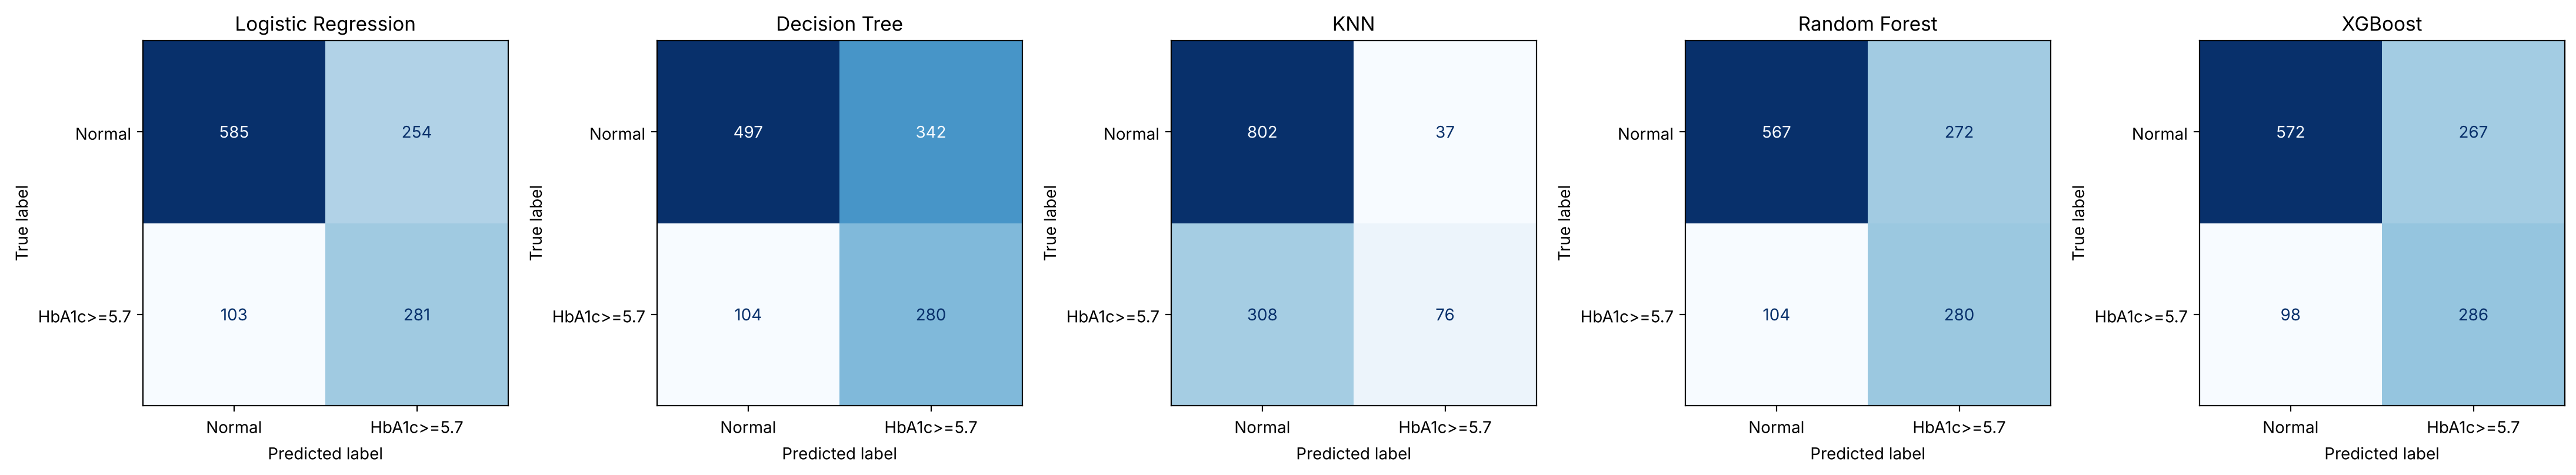

In [8]:
#CONFUSION MATRICES (all models)
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, name in zip(axes, best):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (probs[name] >= 0.5).astype(int)),
                           display_labels=["Normal", "HbA1c>=5.7"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

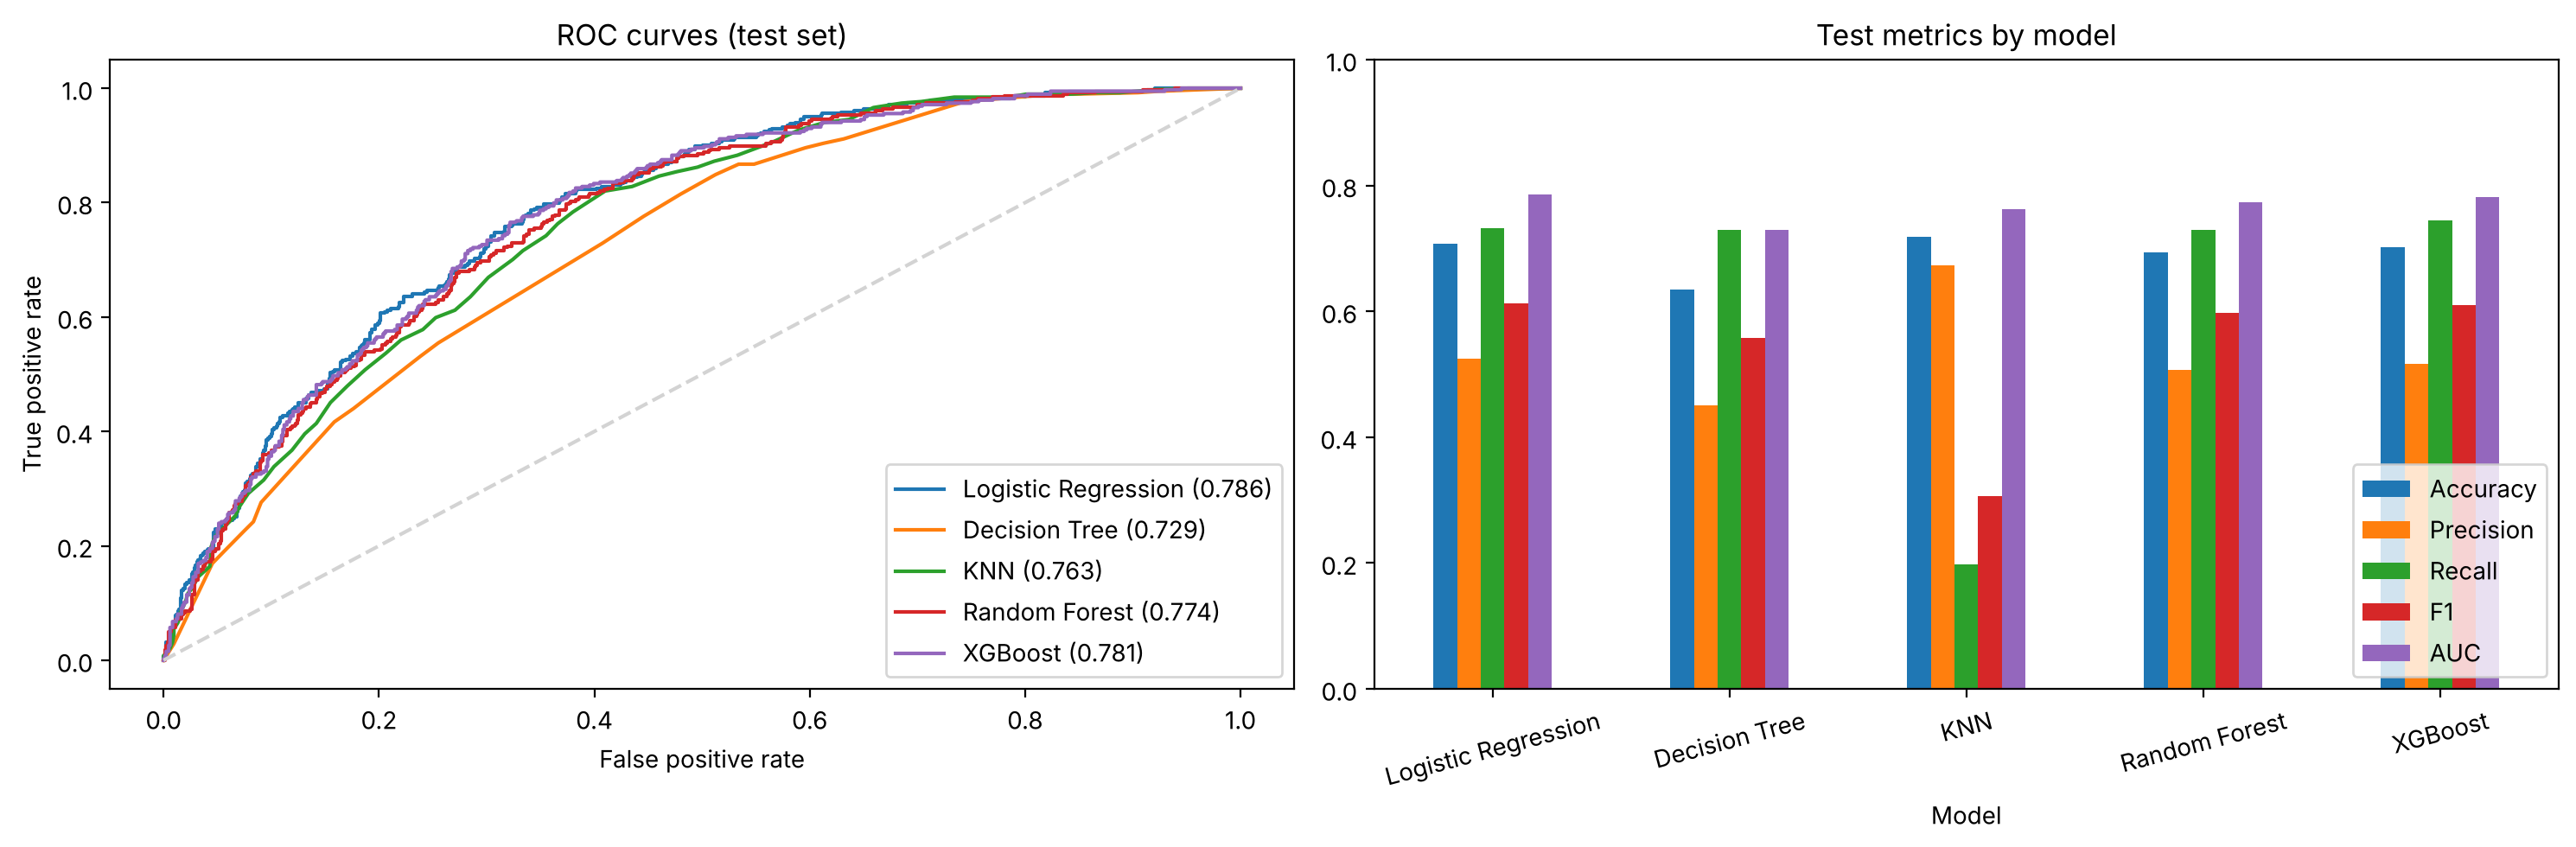

In [9]:
#ROC CURVES + METRICS GRAPH
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name in best:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, probs[name]):.3f})")
axes[0].plot([0, 1], [0, 1], color="lightgrey", ls="--")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test set)")
axes[0].legend()
results[["Accuracy", "Precision", "Recall", "F1", "AUC"]].plot(kind="bar", ax=axes[1], rot=15)
axes[1].set_ylim(0, 1)
axes[1].set_title("Test metrics by model")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [10]:
#FINDRISC
age = nh["age"]
s = np.select([age < 45, age < 55, age < 65], [0, 2, 3], 4)
s = s + np.select([nh["bmi"] < 25, nh["bmi"] <= 30], [0, 1], 3)
w = nh["waist_circ_cm"]
s = s + np.where(nh["gender"] == 1, np.select([w < 94, w <= 102], [0, 3], 4), np.select([w < 80, w <= 88], [0, 3], 4))
s = s + np.where(X["active_min"] >= 210, 0, 2) + np.where(nh["high_bp_meds"] == 1, 2, 0) + np.where(nh["prediab_diag"] == 1, 5, 0)
nh["findrisc"] = np.where(nh["bmi"].isna() | w.isna(), np.nan, s)
ok = nh["findrisc"].notna()
print("FINDRISC AUC: %.3f | undiagnosed: %.3f" % (roc_auc_score(y[ok], nh.loc[ok, "findrisc"]),
                                                  roc_auc_score(nh.loc[ok, "undiagnosed"], nh.loc[ok, "findrisc"])))

FINDRISC AUC: 0.728 | undiagnosed: 0.752


In [11]:
#FEWER QUESTIONS (FORWARD SELECTION)
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, C=0.1))
pool = ["age", "male", "bmi", "waist", "height", "waist_height", "sys_bp", "high_bp", "bp_med", "high_chol",
        "told_prediab", "smoker", "alcohol", "active_min", "sitting_min", "heart_disease", "education"]
all_auc = cross_val_score(lr, X[pool], y, cv=cv, scoring="roc_auc").mean()
selected, curve = [], []
for k in range(10):
    scores = {f: cross_val_score(lr, X[selected + [f]], y, cv=cv, scoring="roc_auc").mean() for f in pool if f not in selected}
    f = max(scores, key=scores.get)
    selected.append(f)
    curve.append(scores[f])
    print(k + 1, f, round(scores[f], 3))
print("All 17 questions:", round(all_auc, 3))

1 age 0.682


2 waist_height 0.727


3 told_prediab 0.751


4 education 0.761


5 bp_med 0.763


6 sitting_min 0.764


7 male 0.764


8 height 0.765


9 bmi 0.765


10 alcohol 0.765
All 17 questions: 0.765


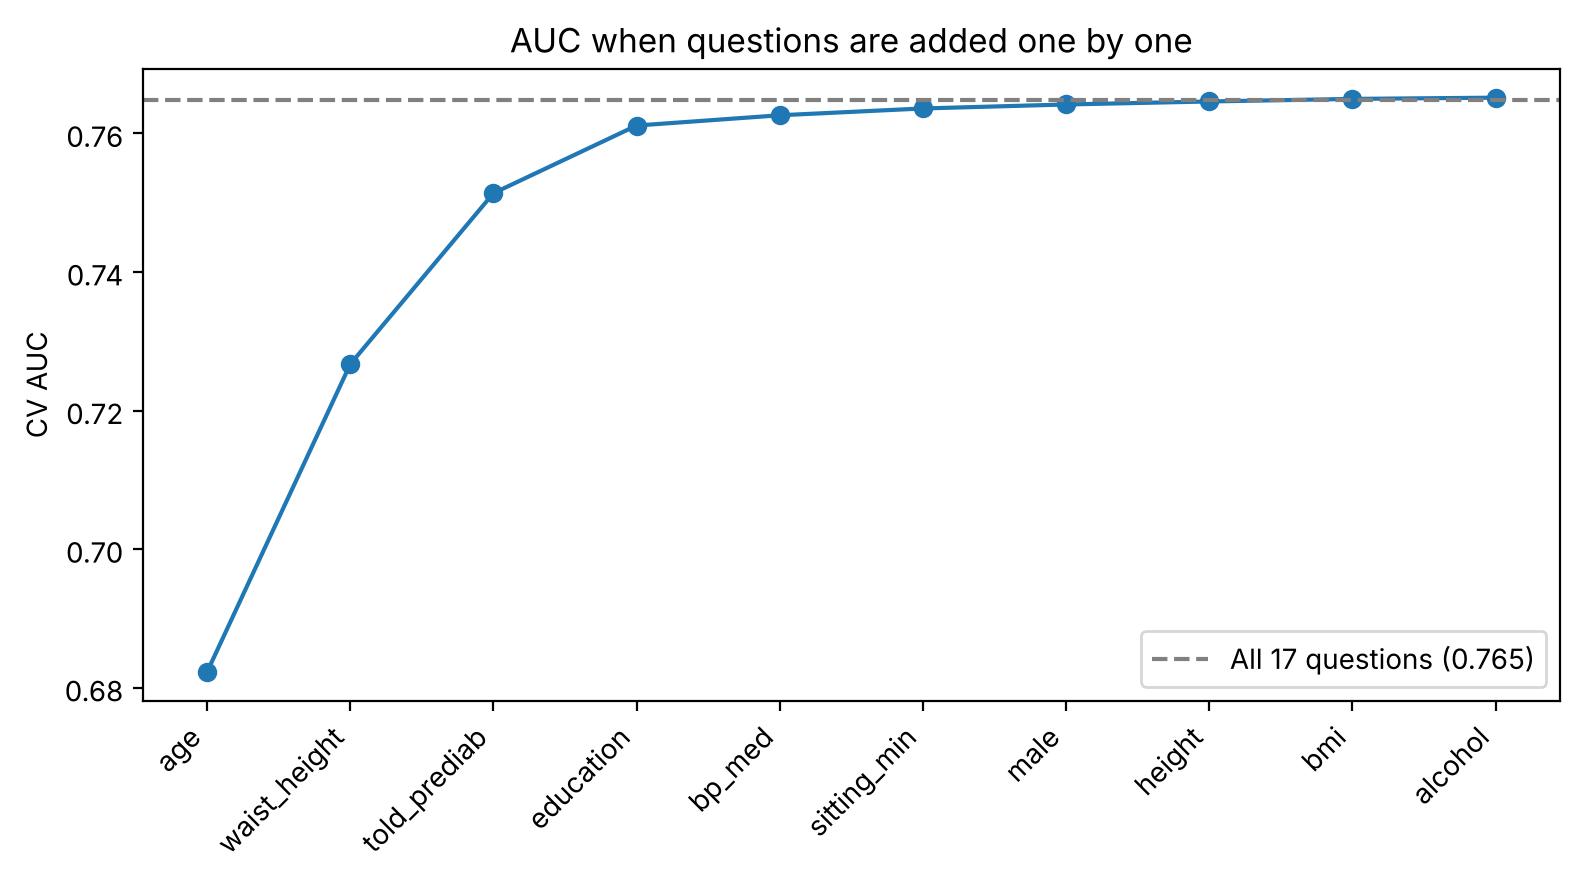

In [12]:
#FEWER QUESTIONS GRAPH
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 11), curve, marker="o")
plt.axhline(all_auc, color="grey", ls="--", label=f"All 17 questions ({all_auc:.3f})")
plt.xticks(range(1, 11), selected, rotation=45, ha="right")
plt.ylabel("CV AUC")
plt.title("AUC when questions are added one by one")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
#DIARISK-5 POINT SCORE
def diarisk_items(df, X):
    q = pd.DataFrame(index=df.index)
    q["age_35_44"] = df["age"].between(35, 44).astype(int)
    q["age_45_54"] = df["age"].between(45, 54).astype(int)
    q["age_55_64"] = df["age"].between(55, 64).astype(int)
    q["age_65+"] = (df["age"] >= 65).astype(int)
    q["waist_height_0.5_0.6"] = X["waist_height"].between(0.5, 0.6, inclusive="left").astype(int)
    q["waist_height_0.6+"] = (X["waist_height"] >= 0.6).astype(int)
    q["told_prediabetes"] = X["told_prediab"]
    q["high_school_or_less"] = (X["education"] <= 3).astype(int)
    q["bp_medicine"] = X["bp_med"]
    return q

Q = diarisk_items(nh, X)
lr6 = LogisticRegression(max_iter=2000).fit(Q.loc[X_train.index], y_train)
points = pd.Series(np.round(lr6.coef_[0] / 0.25).astype(int), index=Q.columns)
print(points)
nh["diarisk5"] = Q @ points
print("DiaRisk-5 test AUC: %.3f | undiagnosed: %.3f" % (roc_auc_score(y_test, nh.loc[X_test.index, "diarisk5"]),
                                                        roc_auc_score(und_test, nh.loc[X_test.index, "diarisk5"])))

age_35_44               2
age_45_54               5
age_55_64               5
age_65+                 6
waist_height_0.5_0.6    1
waist_height_0.6+       4
told_prediabetes        5
high_school_or_less     2
bp_medicine             1
dtype: int64
DiaRisk-5 test AUC: 0.752 | undiagnosed: 0.786


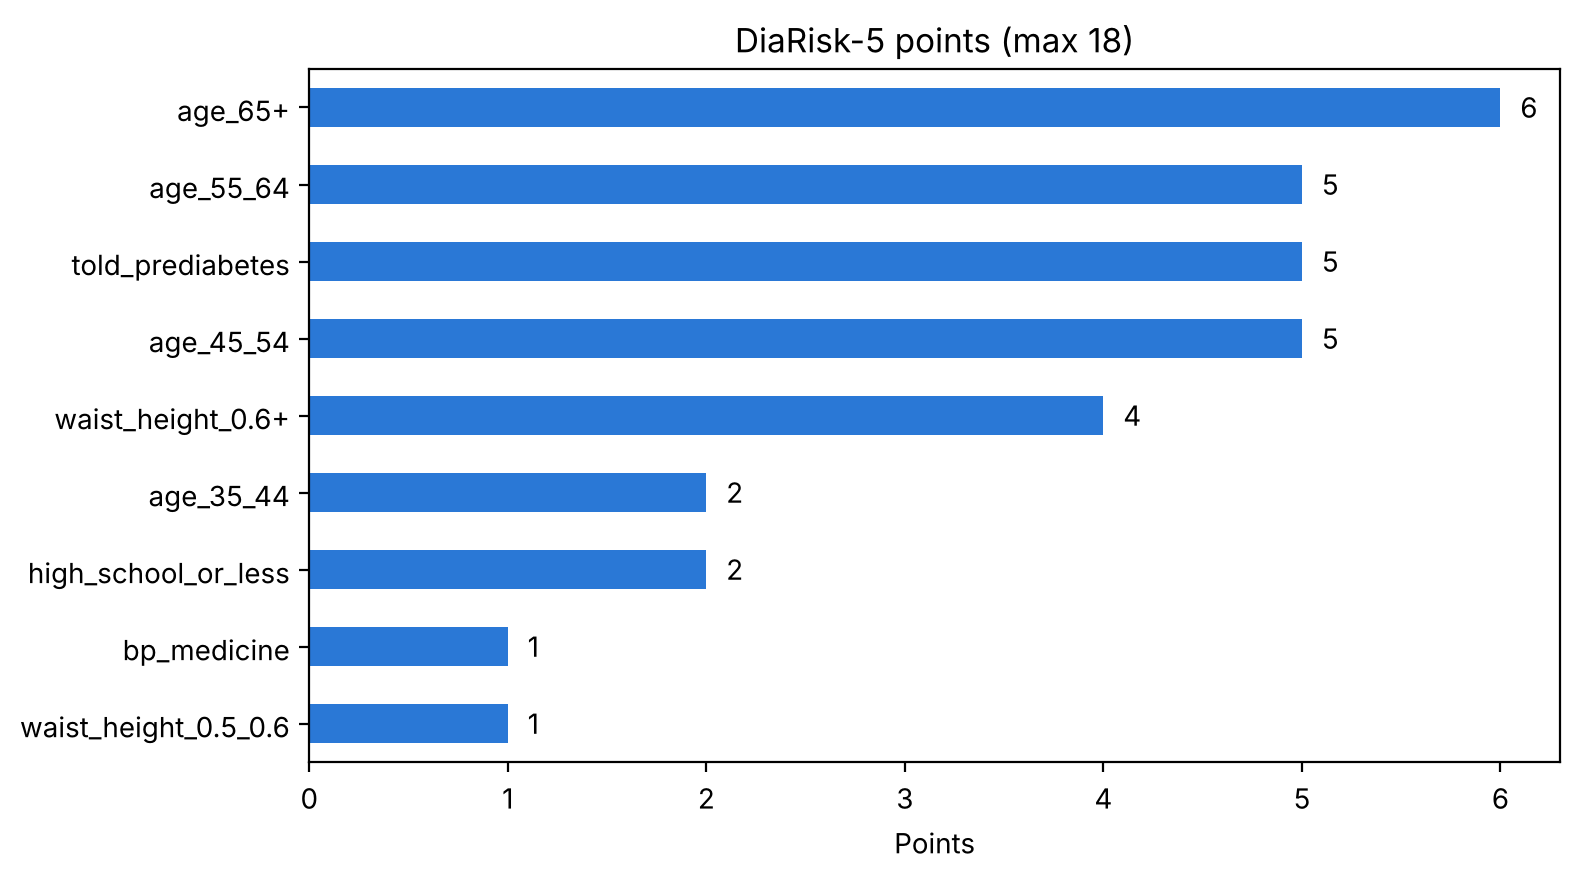

In [14]:
#DIARISK-5 POINTS GRAPH
plt.figure(figsize=(8, 4.5))
points.sort_values().plot(kind="barh", color="#2a78d6")
for i, v in enumerate(points.sort_values()):
    plt.text(v + 0.1, i, str(v), va="center")
plt.xlabel("Points")
plt.title("DiaRisk-5 points (max %d)" % (points[["age_65+", "waist_height_0.6+", "told_prediabetes", "high_school_or_less", "bp_medicine"]].sum()))
plt.tight_layout()
plt.show()

In [15]:
#FINDRISC VS MODELS (SAME REFERRAL RATE)
oof = pd.DataFrame(index=nh.index)
for name in ["Logistic Regression", "XGBoost"]:
    oof[name] = cross_val_predict(best[name], X, y, cv=cv, method="predict_proba")[:, 1]
oof["DiaRisk-5"] = 0.0
for tr, te in cv.split(Q, y):
    m = LogisticRegression(max_iter=2000).fit(Q.iloc[tr], y.iloc[tr])
    oof.iloc[te, oof.columns.get_loc("DiaRisk-5")] = Q.iloc[te] @ np.round(m.coef_[0] / 0.25)
oof["FINDRISC"] = nh["findrisc"]

rate = (nh.loc[ok, "findrisc"] >= 12).mean()
print("FINDRISC >= 12 sends %.1f%% of people to a blood test" % (100 * rate))
found = {}
for col in ["FINDRISC", "DiaRisk-5", "Logistic Regression", "XGBoost"]:
    sc = oof.loc[ok, col] + np.random.RandomState(0).uniform(0, 1e-6, ok.sum())
    flag = sc >= sc.quantile(1 - rate)
    found[col] = [100 * flag[nh.loc[ok, "undiagnosed"] == 1].mean(), 100 * flag[y[ok] == 1].mean(),
                  roc_auc_score(nh.loc[ok, "undiagnosed"], sc)]
found = pd.DataFrame(found, index=["% undiagnosed diabetes found", "% prediabetes/diabetes found", "AUC undiagnosed"]).T
found = found.round({"% undiagnosed diabetes found": 1, "% prediabetes/diabetes found": 1, "AUC undiagnosed": 3})
found

FINDRISC >= 12 sends 27.4% of people to a blood test


,% undiagnosed diabetes found,% prediabetes/diabetes found,AUC undiagnosed
FINDRISC,61.1,47.9,0.753
DiaRisk-5,66.0,49.5,0.762
Logistic Regression,69.4,51.3,0.806
XGBoost,71.5,50.4,0.796


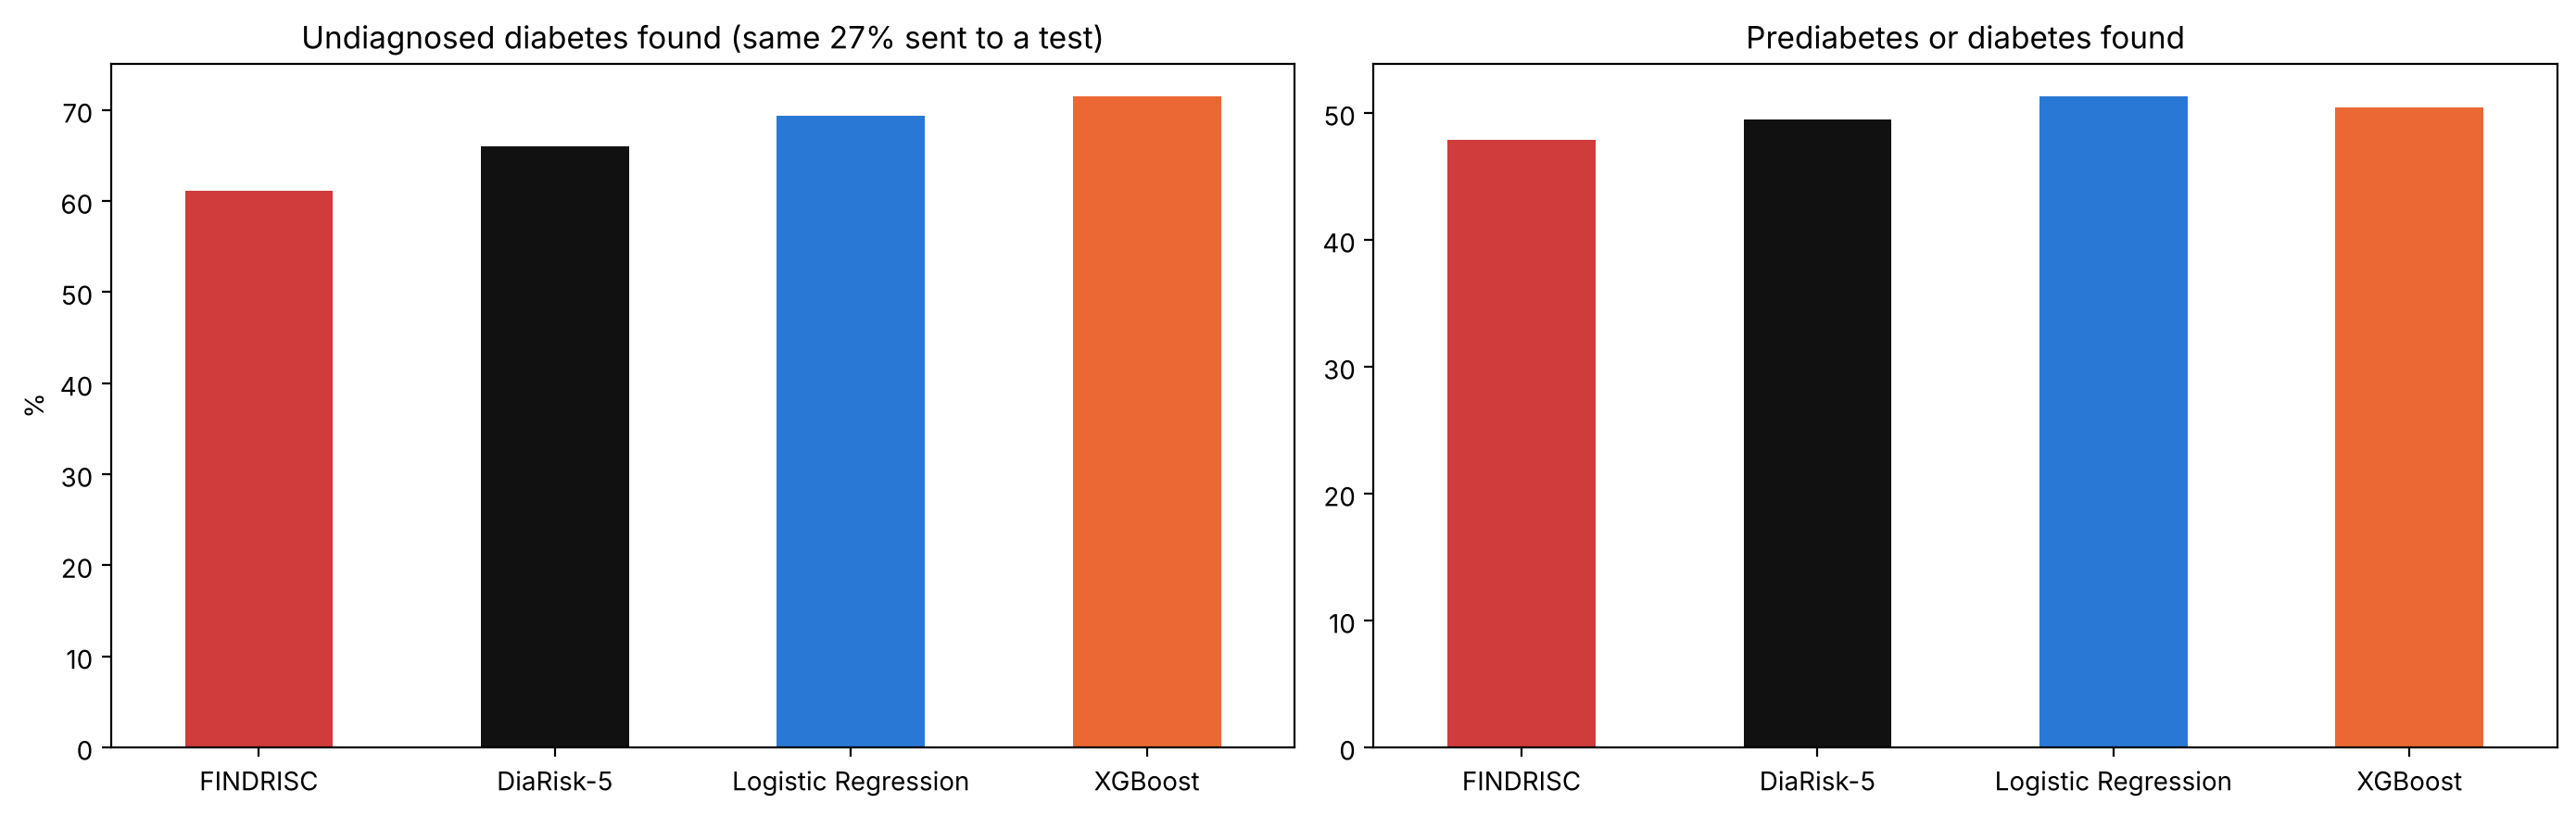

In [16]:
#FINDRISC VS MODELS GRAPH
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
found["% undiagnosed diabetes found"].plot(kind="bar", ax=axes[0], color=["#d03b3b", "#111111", "#2a78d6", "#eb6834"], rot=0)
axes[0].set_title("Undiagnosed diabetes found (same %.0f%% sent to a test)" % (100 * rate))
axes[0].set_ylabel("%")
found["% prediabetes/diabetes found"].plot(kind="bar", ax=axes[1], color=["#d03b3b", "#111111", "#2a78d6", "#eb6834"], rot=0)
axes[1].set_title("Prediabetes or diabetes found")
plt.tight_layout()
plt.show()

In [17]:
#FEATURE IMPORTANCE
imp = permutation_importance(best["Logistic Regression"], X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)
print(importance.head(10).round(3))

age             0.081
told_prediab    0.026
race_black      0.011
waist_height    0.010
race_white      0.009
education       0.007
waist           0.006
foreign_born    0.006
high_chol       0.003
male            0.003
dtype: float64


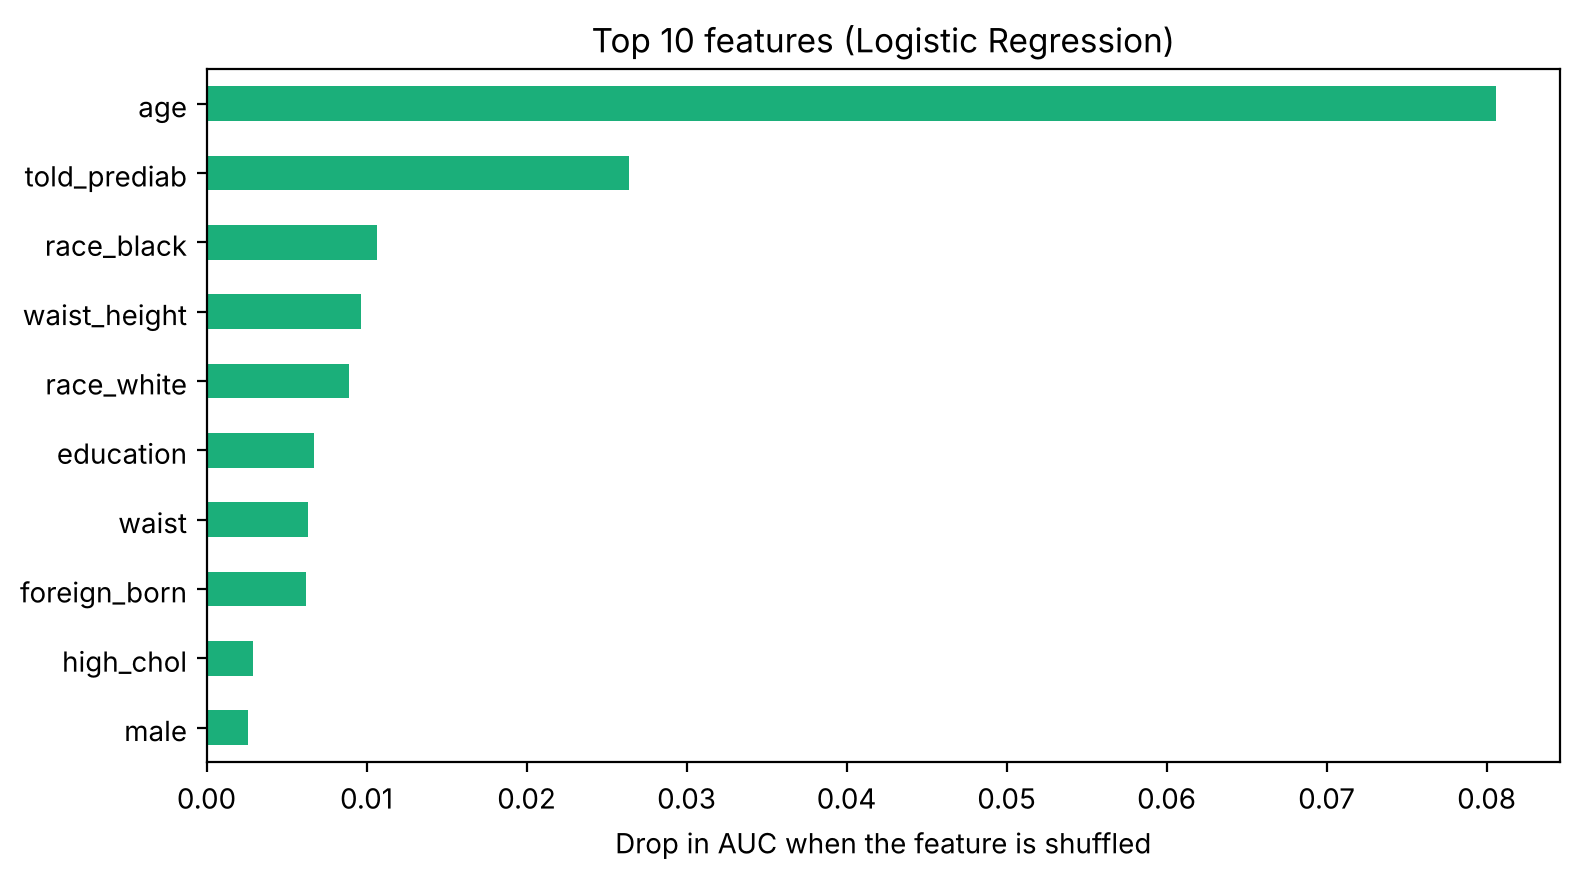

In [18]:
#FEATURE IMPORTANCE GRAPH
plt.figure(figsize=(8, 4.5))
importance.head(10).sort_values().plot(kind="barh", color="#1baf7a")
plt.xlabel("Drop in AUC when the feature is shuffled")
plt.title("Top 10 features (Logistic Regression)")
plt.tight_layout()
plt.show()

In [19]:
#FAIRNESS (SDG 10)
test = nh.loc[X_test.index].copy()
test["p"] = probs["Logistic Regression"]
test["pred"] = (test["p"] >= 0.5).astype(int)
test["group_income"] = np.where(test["poverty_ratio"] < 1.3, "Low income", "Higher income")
test.loc[test["poverty_ratio"].isna(), "group_income"] = np.nan
test["group_sex"] = np.where(test["gender"] == 1, "Men", "Women")
fair = []
for col in ["group_income", "group_sex"]:
    for g, d in test.dropna(subset=[col]).groupby(col):
        fair.append([g, len(d), roc_auc_score(d["target"], d["p"]), recall_score(d["target"], d["pred"])])
fair = pd.DataFrame(fair, columns=["Group", "n", "AUC", "Recall"]).set_index("Group").round(3)
fair

,n,AUC,Recall
Group,,,
Higher income,854,0.810,0.742
Low income,202,0.756,0.754
Men,563,0.759,0.734
Women,660,0.807,0.730


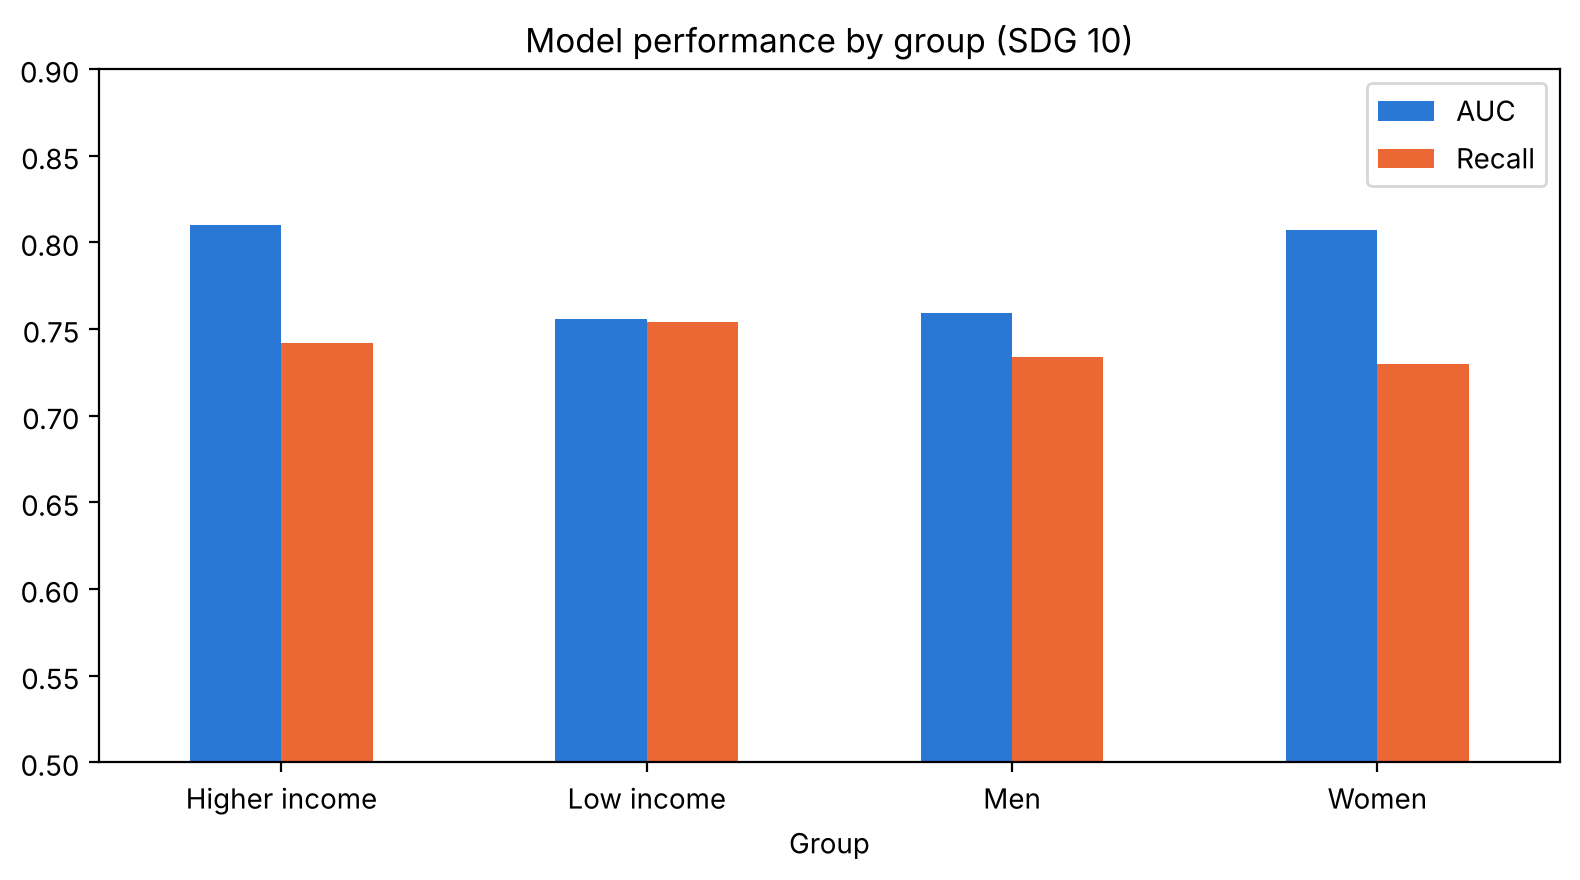

In [20]:
#FAIRNESS GRAPH
fair[["AUC", "Recall"]].plot(kind="bar", figsize=(8, 4.5), rot=0, color=["#2a78d6", "#eb6834"])
plt.ylim(0.5, 0.9)
plt.title("Model performance by group (SDG 10)")
plt.tight_layout()
plt.show()

In [21]:
#BRFSS TIME CONSISTENCY
feat = ["HighBP", "HighChol", "CholCheck", "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity",
        "NoDocbcCost", "GenHlth", "MentHlth", "PhysHlth", "DiffWalk", "Sex", "Age"]
b15 = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv").drop_duplicates()
b15 = b15[b15["BMI"] <= 70]
b15["Diabetes"] = (b15["Diabetes_012"] == 2).astype(int)
b_train, b_test = train_test_split(b15, test_size=0.25, stratify=b15["Diabetes"], random_state=42)

xgb_b = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, eval_metric="logloss", n_jobs=4, random_state=42,
                      scale_pos_weight=(1 - b_train["Diabetes"].mean()) / b_train["Diabetes"].mean())
xgb_b.fit(b_train[feat], b_train["Diabetes"])

years = {"2015": b_test}
for yr in ["2019", "2021", "2023"]:
    d = pd.read_csv(f"cdc_brfss_diabetes_{yr}.csv").drop_duplicates()
    years[yr] = d[d["BMI"] <= 70].rename(columns={"Diabetes_binary": "Diabetes"})

time_res = pd.DataFrame({yr: [len(d), roc_auc_score(d["Diabetes"], xgb_b.predict_proba(d[feat])[:, 1]),
                              recall_score(d["Diabetes"], xgb_b.predict(d[feat]))] for yr, d in years.items()},
                        index=["n", "AUC", "Recall"]).T
time_res.round(3)

,n,AUC,Recall
2015,57300.0,0.812,0.777
2019,223299.0,0.810,0.776
2021,223119.0,0.809,0.754
2023,238825.0,0.798,0.766


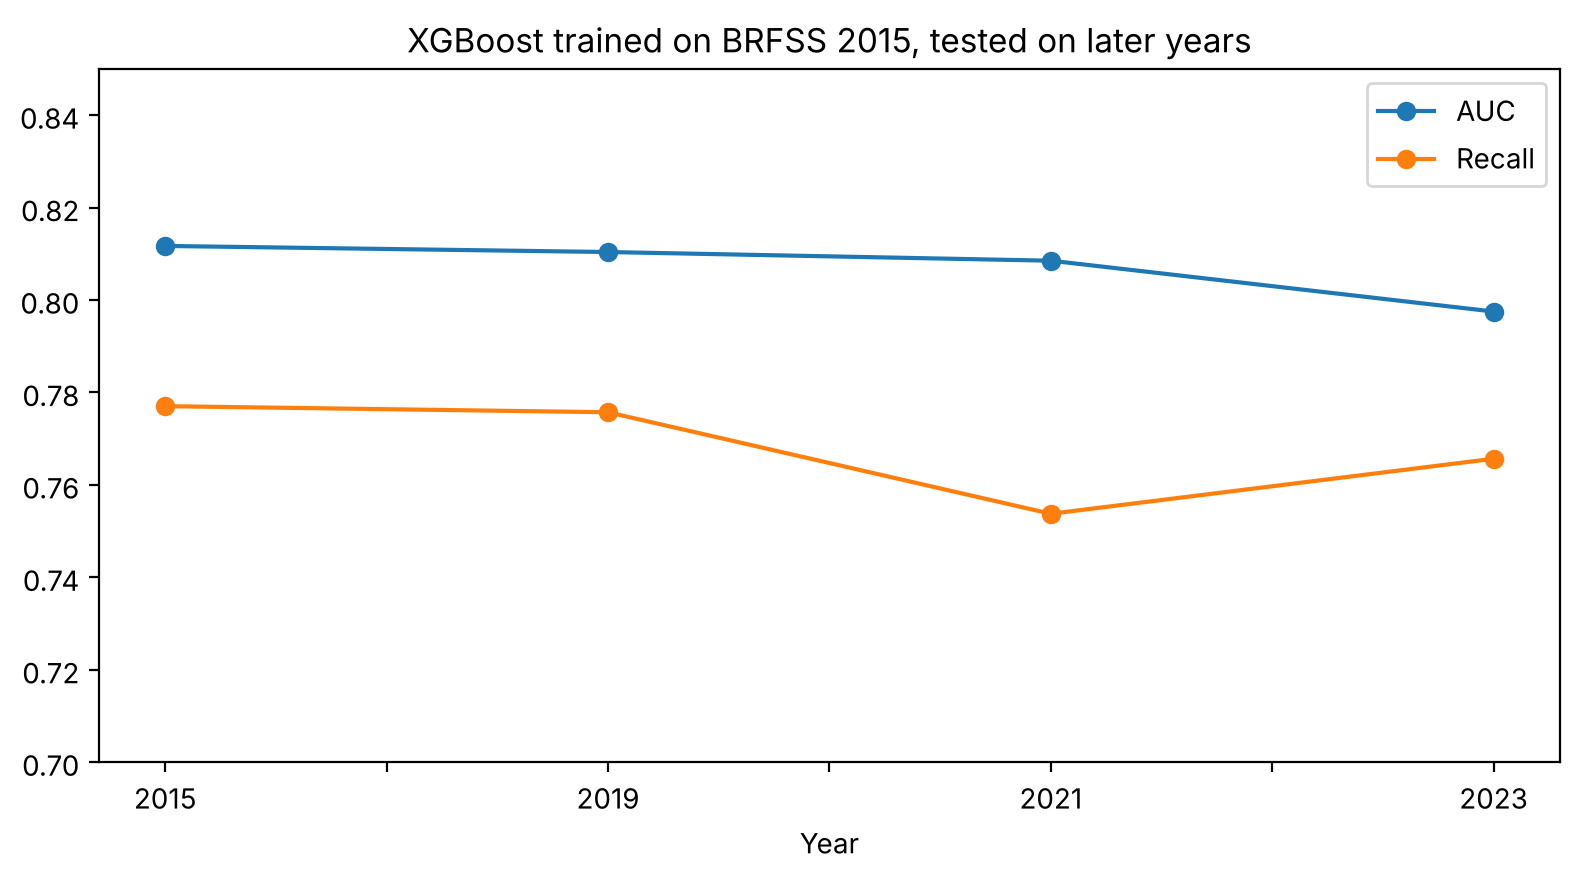

In [22]:
#BRFSS TIME CONSISTENCY GRAPH
time_res[["AUC", "Recall"]].plot(kind="line", marker="o", figsize=(8, 4.5))
plt.ylim(0.7, 0.85)
plt.title("XGBoost trained on BRFSS 2015, tested on later years")
plt.xlabel("Year")
plt.tight_layout()
plt.show()

In [23]:
#TURKIYE COMPARISON
tr = pd.read_csv("turkiye_saglik_ozet.csv")
full = pd.read_csv("nhanes_2021_2023_full.csv")
full = full[full["hba1c"].notna()]
compare = pd.DataFrame({
    "Self-reported diabetes (%)": [100 * full["diab_diag"].mean(),
                                   tr.query("source == 'TUIK 2025' and indicator == 'Diabetes'")["value"].iloc[0]],
    "Measured diabetes, HbA1c (%)": [100 * ((full["diab_diag"] == 1) | (full["hba1c"] >= 6.5)).mean(),
                                     tr.query("source == 'WHO STEPS 2017' and indicator == 'Diabetes' and sex == 'Total'")["value"].iloc[0]]},
    index=["USA (NHANES)", "Turkiye (TUIK / WHO STEPS)"]).round(1)
compare["Gap"] = compare["Measured diabetes, HbA1c (%)"] - compare["Self-reported diabetes (%)"]
print(compare)
print("DiaRisk-5 questions:", list(Q.columns))

                            Self-reported diabetes (%)  \
USA (NHANES)                                      14.2   
Turkiye (TUIK / WHO STEPS)                        11.9   

                            Measured diabetes, HbA1c (%)  Gap  
USA (NHANES)                                        16.9  2.7  
Turkiye (TUIK / WHO STEPS)                          13.3  1.4  
DiaRisk-5 questions: ['age_35_44', 'age_45_54', 'age_55_64', 'age_65+', 'waist_height_0.5_0.6', 'waist_height_0.6+', 'told_prediabetes', 'high_school_or_less', 'bp_medicine']


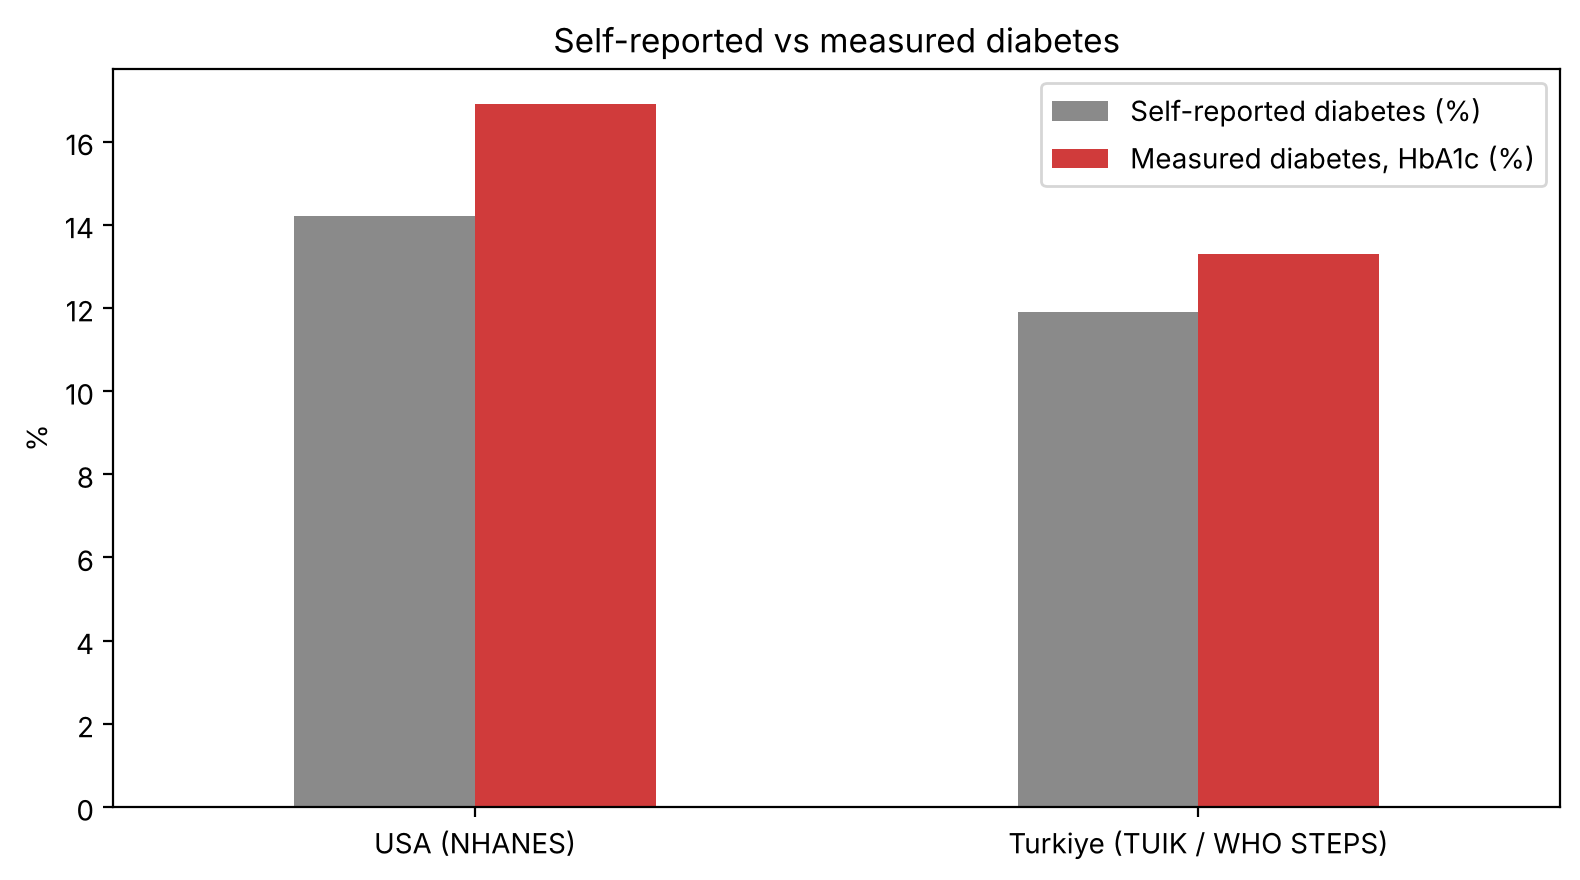

In [24]:
#TURKIYE COMPARISON GRAPH
compare[["Self-reported diabetes (%)", "Measured diabetes, HbA1c (%)"]].plot(kind="bar", figsize=(8, 4.5), rot=0, color=["#8a8a8a", "#d03b3b"])
plt.ylabel("%")
plt.title("Self-reported vs measured diabetes")
plt.tight_layout()
plt.show()

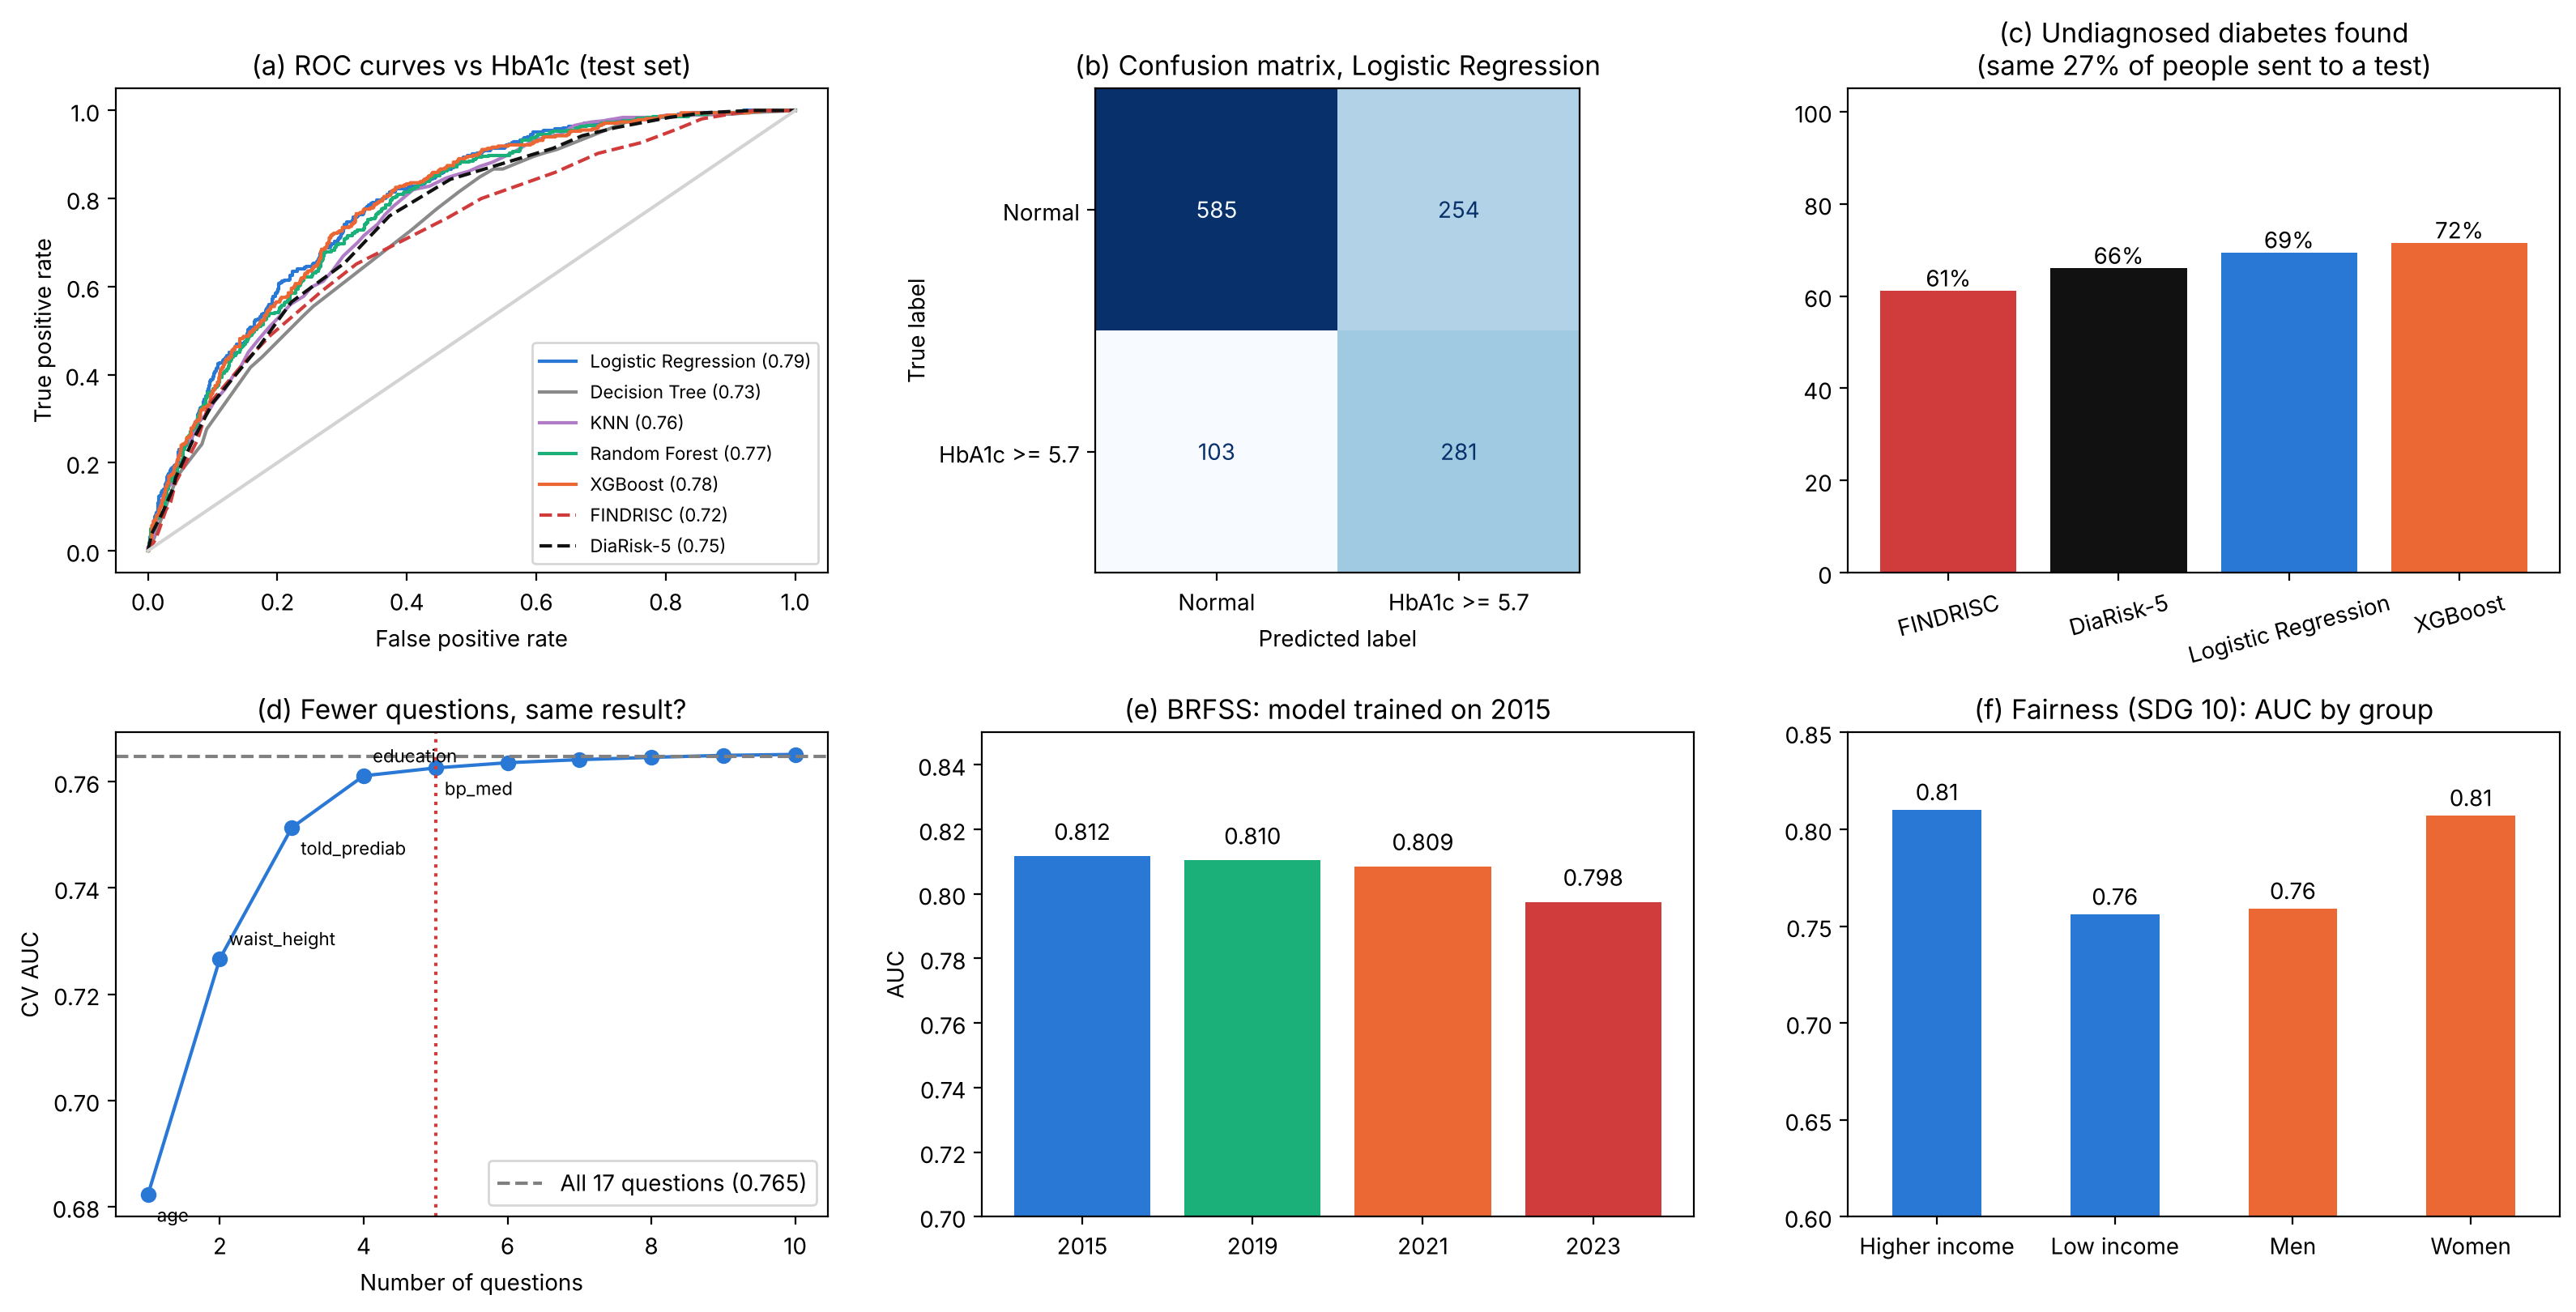

In [25]:
#SUMMARY FIGURE (REPORT)
fig, axes = plt.subplots(2, 3, figsize=(16, 8.2))

ax = axes[0, 0]
for name, col in zip(best, ["#2a78d6", "#8a8a8a", "#b07cc6", "#1baf7a", "#eb6834"]):
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, color=col, label=f"{name} ({roc_auc_score(y_test, probs[name]):.2f})")
for col_, name, c in [("findrisc", "FINDRISC", "#d03b3b"), ("diarisk5", "DiaRisk-5", "#111111")]:
    t = nh.loc[X_test.index]
    m = t[col_].notna()
    fpr, tpr, _ = roc_curve(y_test[m], t.loc[m, col_])
    ax.plot(fpr, tpr, color=c, ls="--", label=f"{name} ({roc_auc_score(y_test[m], t.loc[m, col_]):.2f})")
ax.plot([0, 1], [0, 1], color="lightgrey")
ax.set_title("(a) ROC curves vs HbA1c (test set)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(fontsize=8)

ConfusionMatrixDisplay(confusion_matrix(y_test, (probs["Logistic Regression"] >= 0.5).astype(int)),
                       display_labels=["Normal", "HbA1c >= 5.7"]).plot(ax=axes[0, 1], cmap="Blues", colorbar=False)
axes[0, 1].set_title("(b) Confusion matrix, Logistic Regression")

ax = axes[0, 2]
v = found["% undiagnosed diabetes found"]
bars = ax.bar(v.index, v.values, color=["#d03b3b", "#111111", "#2a78d6", "#eb6834"])
for b_, val in zip(bars, v.values):
    ax.text(b_.get_x() + b_.get_width() / 2, val + 1, f"{val:.0f}%", ha="center")
ax.set_ylim(0, 105)
ax.set_title(f"(c) Undiagnosed diabetes found\n(same {100 * rate:.0f}% of people sent to a test)")
ax.tick_params(axis="x", rotation=15)

ax = axes[1, 0]
ax.plot(range(1, 11), curve, marker="o", color="#2a78d6")
ax.axhline(all_auc, color="grey", ls="--", label=f"All 17 questions ({all_auc:.3f})")
ax.axvline(5, color="#d03b3b", ls=":")
for i, f in enumerate(selected[:5]):
    ax.annotate(f, (i + 1, curve[i]), textcoords="offset points", xytext=(4, -12 if i % 2 == 0 else 6), fontsize=8)
ax.set_xlabel("Number of questions")
ax.set_ylabel("CV AUC")
ax.set_title("(d) Fewer questions, same result?")
ax.legend()

ax = axes[1, 1]
ax.bar(time_res.index, time_res["AUC"], color=["#2a78d6", "#1baf7a", "#eb6834", "#d03b3b"])
for i, val in enumerate(time_res["AUC"]):
    ax.text(i, val + 0.005, f"{val:.3f}", ha="center")
ax.set_ylim(0.7, 0.85)
ax.set_title("(e) BRFSS: model trained on 2015")
ax.set_ylabel("AUC")

ax = axes[1, 2]
fair["AUC"].plot(kind="bar", ax=ax, color=["#2a78d6", "#2a78d6", "#eb6834", "#eb6834"], rot=0)
for i, val in enumerate(fair["AUC"]):
    ax.text(i, val + 0.005, f"{val:.2f}", ha="center")
ax.set_ylim(0.6, 0.85)
ax.set_title("(f) Fairness (SDG 10): AUC by group")
ax.set_xlabel("")

plt.tight_layout()
plt.savefig("fig_assignment2.png", dpi=200)
plt.show()